## Earth reflectivity demonstration.
In this notebook, we demonstrate the use of PSG to calculate the reflectivity of Earth. The configuation we use is from the work described in Kofman 2024. For details, see there.

Throughout this notebook, we will be making calls to the PSG server using curl commands. In order for these to work, files will be saved on the users' virtual google colab machine (VM). None of the code will have to be modified to run.

The configuration file will be modified in several steps, gradually changing the complexity to match the published spectrum. The modifications are done by adding an additional line to the **configuration file** using the .append method, saving the file on the VM, and running the API call with the modified configuration file.

Note that no information is lost from the configuration file, and we will see that by changing the parameter to its original value we can obtain the orignal spectrum (this is slightly different from modifying simulations in the browser version, where the configuration file is cleaned up).

**Links:**

Kofman 2024, Planetary Science Journal:
https://iopscience.iop.org/article/10.3847/PSJ/ad6448

This work is funded by SEEC:
https://seec.gsfc.nasa.gov/

In [30]:
import os
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# the configuration file will be downloaded from the github server
os.system('curl https://raw.githubusercontent.com/VincentKofman/Earth/refs/heads/main/Earth_summer.cfg > psg_cfg.txt')

0

For the work in Kofman+24, the spectra were generated in absolute radiance units (i.e. W/sr/m2/um). Let's change these to I/F (geometric albedo), as this may be more familiar.



In [3]:
# We'll open the configuration file
fr = open('psg_cfg.txt')
cfg = fr.readlines()
fr.close()

# We change the units to I/F
cfg.append('<GENERATOR-RADUNITS>rif\n')

# With the units of I/F we dont need to the stellar model
cfg.append('<GENERATOR-CONT-STELLAR>N\n')

# And save the file
fw = open('psg_cfg_rif.txt','w')
fw.writelines(cfg)
fw.close()


In [4]:
# Run simulation using the PSG API
os.system('curl --data-urlencode file@psg_cfg_rif.txt https://psg.gsfc.nasa.gov/api.php > psg_rad.txt')

0

Text(0.5, 1.0, 'Earth Reflectance spectrum')

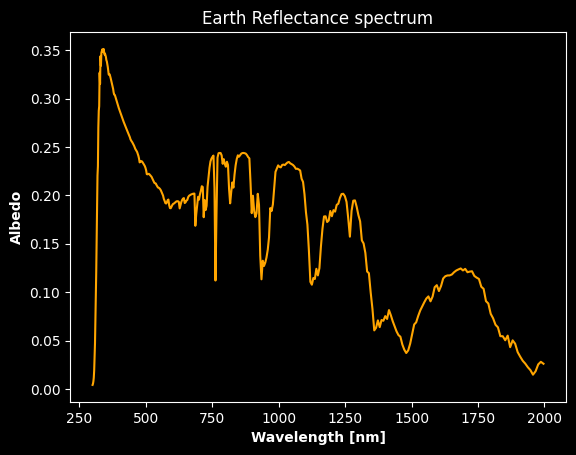

In [8]:
# read the data from the radiation file  (PSG output files are designed to be compatible with numpy's genfromtxt)
data = np.genfromtxt('psg_rad.txt')
# Plot the results

plt.plot(data[:,0], data[:,1],   color='orange')
plt.xlabel('Wavelength [nm]',    weight='bold')
plt.ylabel('Albedo',             weight='bold')
plt.title('Earth Reflectance spectrum')

## step-by-step simulation of Earth's reflectivity
Let's start breaking down the signal by comparing the reflectivity of analogue spectra from increasingly complex simulations.

In [9]:
# By disabling the atmospheric model and disabling surface components,
# we simulate reflected light from a Lambertian sphere from there on we can build the complexity.

# Disable atmospheric model (PUMAS)
cfg.append('<GENERATOR-GAS-MODEL>N\n')

# Disable the surface components
cfg.append('<SURFACE-NSURF>0\n')

fw = open('psg_cfg_ws.txt','w')
fw.writelines(cfg)
fw.close()

In [10]:
os.system('curl --data-urlencode file@psg_cfg_ws.txt https://psg.gsfc.nasa.gov/api.php > psg_rad_white_sphere.txt')

0

In [11]:
# Let's look at the effect of Rayleigh scattering

# Enable the atmospheric model again
cfg.append('<GENERATOR-GAS-MODEL>Y\n')

# For now, we just enable 1 gas (N2)
cfg.append('<ATMOSPHERE-NGAS>1\n')

# Clouds are disabled for now.
cfg.append('<ATMOSPHERE-NAERO>0\n')

fw = open('psg_cfg_rl.txt','w')
fw.writelines(cfg)
fw.close()

In [12]:
os.system('curl --data-urlencode file@psg_cfg_rl.txt https://psg.gsfc.nasa.gov/api.php > psg_rad_rl.txt')


0

Text(0.5, 1.0, 'Earth Reflectance spectrum')

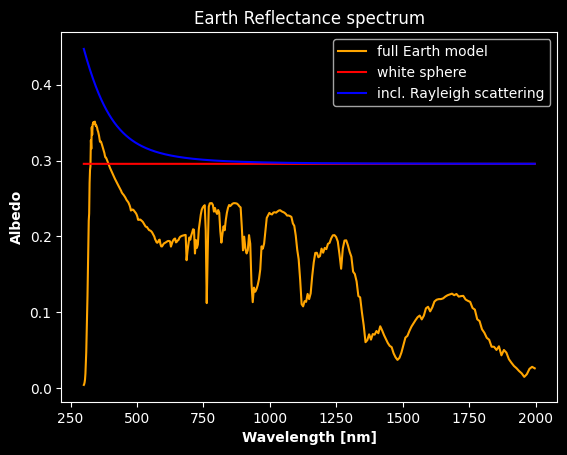

In [13]:
data2 = np.genfromtxt('psg_rad_white_sphere.txt') # white sphere
data3 = np.genfromtxt('psg_rad_rl.txt')           # added Rayleigh scattering
plt.plot(data[:,0], data[:,1], color='orange',  label='full Earth model')
plt.plot(data[:,0], data2[:,1], color='red',    label='white sphere')
plt.plot(data[:,0], data3[:,1], color='blue',   label='incl. Rayleigh scattering')
plt.legend()
plt.xlabel('Wavelength [nm]',weight='bold')
plt.ylabel('Albedo',weight='bold')
plt.title('Earth Reflectance spectrum')

In [16]:
# Now that we have a white sphere, it is relevant to compare what the effect of the surface components is.
# Change the surface back to its original composition for this simulation:
# Ocean     -   65.8%
# Snow/ice  -    2.8%
# Grass     -   13.7%
# Desert    -    7.9%
# Forest    -    8.7%

cfg.append('<SURFACE-NSURF>5\n')

fw = open('psg_cfg_es.txt','w')
fw.writelines(cfg)
fw.close()

# The albedo of the Earth without clouds is very low (±0.08), let's enable the simulation of clouds.
# For these simulations, 2 types of aerosols are assumed:
# - Liquid water -  10 um size particles    -  profile in configuration file
# - icy water    -  30 um size particles    -  profile in cfg file

cfg.append('<ATMOSPHERE-NAERO>2\n')

fw = open('psg_cfg_esc.txt','w')
fw.writelines(cfg)
fw.close()

In [17]:
os.system('curl --data-urlencode file@psg_cfg_es.txt https://psg.gsfc.nasa.gov/api.php > psg_rad_es.txt')

0

In [18]:
os.system('curl --data-urlencode file@psg_cfg_esc.txt https://psg.gsfc.nasa.gov/api.php > psg_rad_esc.txt')

0

Text(0.5, 1.0, 'Earth Reflectance spectrum')

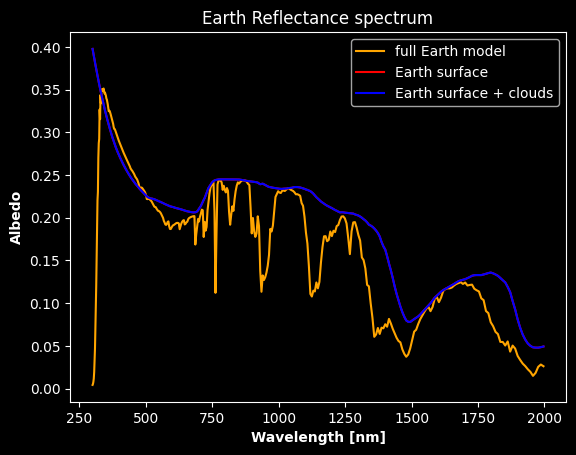

In [19]:
data4 = np.genfromtxt('psg_rad_es.txt')  # Earth surface
data5 = np.genfromtxt('psg_rad_esc.txt') # Earth surface + clouds
plt.plot(data[:,0], data[:,1],  color='orange',  label='full Earth model')
plt.plot(data[:,0], data4[:,1], color='red',     label='Earth surface ')
plt.plot(data[:,0], data5[:,1], color='blue',    label='Earth surface + clouds')
plt.legend()
plt.xlabel('Wavelength [nm]',   weight='bold')
plt.ylabel('Albedo'            ,weight='bold')
plt.title('Earth Reflectance spectrum')

In [20]:
# Now lets add the gases back into this simulation. Six gases are used in this simulation.
# N2  - 78.1%
# CO2 - 400 ppm
# N2O - 0.3 ppm
# O2  - 20.1%
# H2O - 1 x scaler - profile in configuration file
# O3  - 1 x scaler - profile in configuration file


cfg.append('<ATMOSPHERE-NGAS>6\n')

fw = open('psg_cfg_ess_all.txt','w')
fw.writelines(cfg)
fw.close()

os.system('curl -d type=rad --data-urlencode  file@psg_cfg_ess_all.txt https://psg.gsfc.nasa.gov/api.php > psg_rad_ess_al.txt')

0

Text(0.5, 1.0, 'Earth Reflectance spectrum')

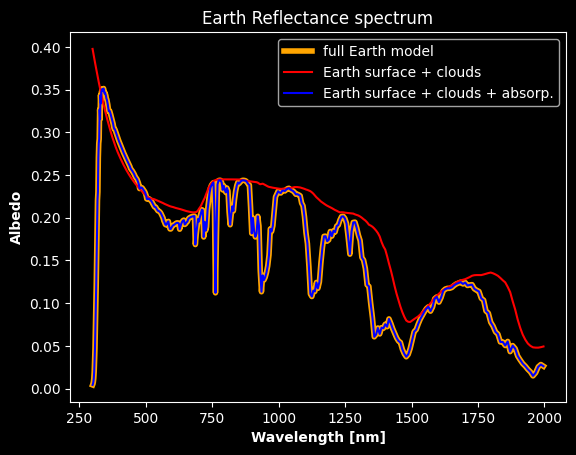

In [21]:
data6 = np.genfromtxt('psg_rad_ess_al.txt')
plt.plot(data[:,0], data[:,1],  color='orange',  label='full Earth model', linewidth= 4)
plt.plot(data[:,0], data5[:,1], color='red',     label='Earth surface + clouds')
plt.plot(data[:,0], data6[:,1], color='blue',    label='Earth surface + clouds + absorp.')
plt.legend()
plt.xlabel('Wavelength [nm]',     weight='bold')
plt.ylabel('Albedo',              weight='bold')
plt.title('Earth Reflectance spectrum')

## The transmittance spectrum
Let's look at the transmittance spectrum, which shows the contributions of the different components in the atmosphere. It is important to understand that the numbers here do not translate into the reflectance spectrum shown above, since it indicates the average *absorption* of the components. Reflection and scattering is *not* included.


In [22]:
os.system('curl -d type=trn --data-urlencode  file@psg_cfg_ess_all.txt https://psg.gsfc.nasa.gov/api.php > psg_trn_ess_al.txt')

0

In [23]:
transmission = np.genfromtxt('psg_trn_ess_al.txt')

In [24]:
fr = open('psg_trn_ess_al.txt')
trn = fr.readlines()
fr.close()

In [25]:
labels = trn[8].split()[1:]
labels[-1] = labels[-1]

Text(0, 0.5, 'Albedo')

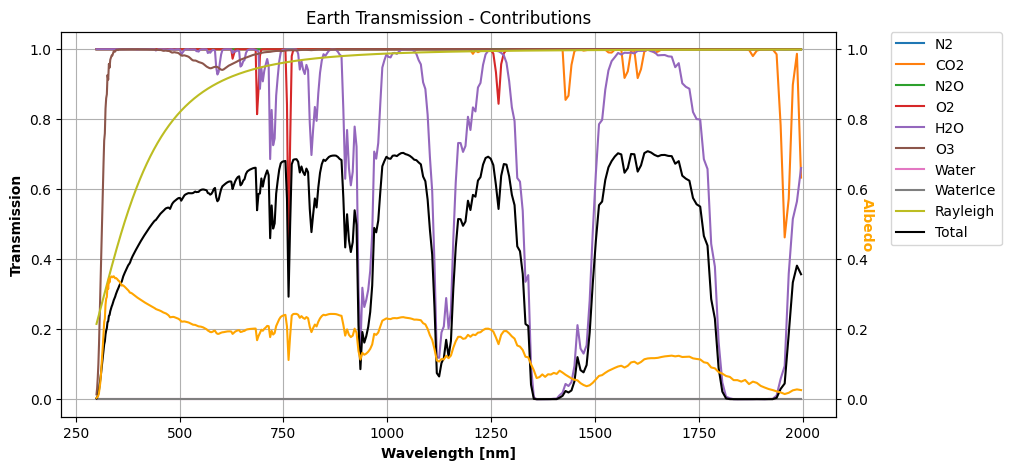

In [31]:
plt.figure(figsize=(10,5))
for i in range(2,len(labels)-1):
  plt.plot(transmission[:,0], transmission[:,i],label=labels[i])
plt.plot(transmission[:,0], transmission[:,1],'black',label=labels[1])
plt.legend(bbox_to_anchor=(1.07, 1), loc='upper left', borderaxespad=0.)

plt.xlabel('Wavelength [nm]',weight='bold')
plt.ylabel('Transmission',weight='bold')
plt.title('Earth Transmission - Contributions')
plt.grid()

plt.twinx()
plt.plot(data[:,0], data[:,1],  color='orange',  label='full Earth model')
plt.ylim(-.05,1.05)
plt.ylabel('Albedo',color='orange',rotation=270,weight='bold')


In this figure, transmission of 1 indicates a transparant atmosphere, 0 means no photons make it through the atmosphere without being absorbed or scattered.

Looking at this figure can help us identify which of the absorptions features in the reflectance spectrum correspond to which feature in the previous figure.

Important to note here as well is that even though water absorption prevents any light in the strong bands around 1350 and 1850 nm from transmitting through the atmosphere, the reflectivity of the Earth is not zero there. This is where the scattering and reflectivity comes in.